# Chương 6. Vector hóa văn bản và phân tích không gian đặc trưng

So sánh BoW, TF-IDF (n-gram 1–3), Word2Vec và [Nâng cao] Sentence Transformer theo: số chiều, độ thưa, cosine similarity trong/giữa lớp, t-SNE và silhouette score.

**Nguyên tắc của chương.**
- Mọi thứ cần học từ dữ liệu (từ vựng và IDF của BoW/TF-IDF, mô hình Word2Vec, phép giảm chiều SVD) **chỉ fit trên tập train**. Hình học của các biểu diễn (cosine, silhouette, t-SNE) được đo trên **toàn bộ tập test** (9.916 review, ít hơn `config.TEXT_SAMPLE_SIZE`), tức trên dữ liệu mà các biểu diễn chưa từng thấy.
- Biểu diễn thưa và Word2Vec dùng cột `clean` của chương 5; Sentence Transformer dùng cột `light` (văn bản tự nhiên, còn chữ hoa và dấu câu).
- "n-gram $n\in\{1,2,3\}$" được hiểu là dải $(1,n)$: $n=2$ gồm cả unigram và bigram, $n=3$ gồm unigram, bigram và trigram.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from dmprep import config
import hashlib
import os
import time

from scipy import sparse, stats
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import normalize


config.set_seed()
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (12, 4)

RESULTS: dict = {}  # mọi score / p-value của chương này được lưu vào đây

In [2]:
clean_path = config.PROCESSED_DIR / "imdb_clean.parquet"
if not clean_path.exists():
    raise FileNotFoundError("Chưa có imdb_clean.parquet: hãy chạy chương 5 (mục 5.5) trước.")
df = pd.read_parquet(clean_path)
train, test = df[df["split"] == "train"].reset_index(drop=True), df[df["split"] == "test"].reset_index(drop=True)
y_train, y_test = train["label"].to_numpy(), test["label"].to_numpy()
assert len(test) <= config.TEXT_SAMPLE_SIZE  # test đủ nhỏ để dùng toàn bộ cho các phép tính nặng

# Mẫu có nhãn dùng để huấn luyện bộ phân loại ở mục 6.4 (phân tầng, cỡ config.TEXT_SAMPLE_SIZE)
sub_idx = train.groupby("label", group_keys=False).sample(n=config.TEXT_SAMPLE_SIZE // 2, random_state=config.SEED).index.to_numpy()
print(f"Train {len(train)}, test {len(test)} (hình học đo trên toàn bộ test), mẫu có nhãn để huấn luyện bộ phân loại: {len(sub_idx)}")
print("Ví dụ cột clean:", train["clean"].iloc[0][:100], "...")
RESULTS.update({"n_train": len(train), "n_test": len(test), "n_labeled_subset": len(sub_idx)})

Train 39662, test 9916 (hình học đo trên toàn bộ test), mẫu có nhãn để huấn luyện bộ phân loại: 10000
Ví dụ cột clean: one reviewers mentioned watching oz episode hooked right exactly happened first thing struck oz brut ...


## 6.1 BoW, TF-IDF và Word2Vec

**BoW (bag-of-words).** Mỗi review là vector đếm số lần xuất hiện của từng từ trong từ vựng (bỏ thứ tự từ).

**TF-IDF.** Giảm trọng số của các từ xuất hiện ở nhiều review. Với từ $t$ và review $d$ (cài đặt mặc định của scikit-learn):
$$\text{tf-idf}(t,d) = \text{tf}(t,d)\cdot\left(\ln\frac{1+N}{1+\text{df}(t)} + 1\right)$$
với $N$ là số review của train, $\text{df}(t)$ là số review chứa $t$; sau đó mỗi hàng được chuẩn hóa L2. Ta thử ba dải n-gram: $(1,1)$, $(1,2)$ và $(1,3)$, và cả BoW $(1,1)$ làm mốc. Tất cả dùng `min_df=5` (bỏ từ hoặc n-gram xuất hiện ở dưới 5 review, vì chương 4 cho thấy 41% từ vựng chỉ xuất hiện một lần) để các cấu hình so sánh công bằng và số chiều không bùng nổ.

**Word2Vec (skip-gram).** Học vector dày đặc $v_w$ cho từng từ bằng cách dự đoán các từ ngữ cảnh quanh một từ giữa: tối đa hóa $\sum_{t}\sum_{-c\le j\le c,\,j\ne0}\ln P(w_{t+j}\mid w_t)$, xấp xỉ bằng lấy mẫu âm (5 mẫu âm). Các từ xuất hiện trong ngữ cảnh giống nhau có vector gần nhau. Ta huấn luyện **trên chính tập train** (cửa sổ 5, `min_count=5`, 100 chiều, 5 epoch). Để tái lập được, ta dùng `workers=1`, seed cố định và hàm băm xác định (hàm băm mặc định của Python thay đổi theo từng lần chạy). **Vector của một review** là trung bình các vector của những từ có trong từ vựng Word2Vec; review không có từ nào trong từ vựng nhận vector 0.

**Độ thưa.** $\text{sparsity}=1-\dfrac{\text{nnz}}{n_{\text{docs}}\times n_{\text{dims}}}$, với nnz là số phần tử khác 0 (tính trên ma trận test). Biểu diễn dày đặc (Word2Vec) có độ thưa gần 0.

In [3]:
def stable_hash(s: str) -> int:
    return int(hashlib.md5(s.encode()).hexdigest(), 16) % 2 ** 32


VECTORIZERS = {
    "BoW (1-gram)": CountVectorizer(min_df=5),
    "TF-IDF (1-gram)": TfidfVectorizer(min_df=5),
    "TF-IDF (1-2 gram)": TfidfVectorizer(min_df=5, ngram_range=(1, 2)),
    "TF-IDF (1-3 gram)": TfidfVectorizer(min_df=5, ngram_range=(1, 3)),
}
REP_TRAIN, REP_TEST, rows = {}, {}, {}
for name, vec in VECTORIZERS.items():
    t0 = time.time()
    REP_TRAIN[name] = vec.fit_transform(train["clean"])  # chỉ fit trên train
    REP_TEST[name] = vec.transform(test["clean"])
    X = REP_TEST[name]
    rows[name] = {"số chiều": X.shape[1], "nnz / review": X.nnz / X.shape[0], "sparsity ratio": 1 - X.nnz / (X.shape[0] * X.shape[1]), "thời gian fit (s)": time.time() - t0}

from gensim.models import Word2Vec

t0 = time.time()
w2v = Word2Vec(sentences=[s.split() for s in train["clean"]], vector_size=100, window=5, min_count=5, sg=1, epochs=5, workers=1, seed=config.SEED, hashfxn=stable_hash)
w2v_time = time.time() - t0


def doc_vectors(texts: pd.Series) -> np.ndarray:
    """Trung bình vector các từ có trong từ vựng Word2Vec; review không có từ nào nhận vector 0."""
    out = np.zeros((len(texts), w2v.vector_size), dtype=np.float32)
    for i, s in enumerate(texts):
        vecs = [w2v.wv[w] for w in s.split() if w in w2v.wv]
        if vecs:
            out[i] = np.mean(vecs, axis=0)
    return out


REP_TRAIN["Word2Vec (trung bình)"], REP_TEST["Word2Vec (trung bình)"] = doc_vectors(train["clean"]), doc_vectors(test["clean"])
W = REP_TEST["Word2Vec (trung bình)"]
rows["Word2Vec (trung bình)"] = {"số chiều": W.shape[1], "nnz / review": np.count_nonzero(W) / W.shape[0], "sparsity ratio": 1 - np.count_nonzero(W) / W.size, "thời gian fit (s)": w2v_time}
n_zero_docs = int((np.abs(W).sum(axis=1) == 0).sum())
rep_table = pd.DataFrame(rows).T
display(rep_table.round(6))
print(f"Word2Vec: từ vựng {len(w2v.wv):,} từ; review test không có từ nào trong từ vựng: {n_zero_docs}")
print("Láng giềng gần nhất trong không gian Word2Vec (cosine):")
neighbors = {w: [x for x, _ in w2v.wv.most_similar(w, topn=5)] for w in ["good", "bad", "terrible", "boring", "excellent"]}
for w, nb_ in neighbors.items():
    print(f"  {w}: {nb_}")
RESULTS.update({"rep_table": rep_table.round(8).to_dict("index"), "w2v_vocab": len(w2v.wv), "w2v_zero_docs_test": n_zero_docs, "w2v_neighbors": neighbors})

,số chiều,nnz / review,sparsity ratio,thời gian fit (s)
BoW (1-gram),32951.0,96.999697,0.997056,6.349984
TF-IDF (1-gram),32951.0,96.999697,0.997056,7.049201
TF-IDF (1-2 gram),143441.0,135.994554,0.999052,17.711994
TF-IDF (1-3 gram),158199.0,138.973981,0.999122,28.411506
Word2Vec (trung bình),100.0,100.000000,0.000000,217.018414


Word2Vec: từ vựng 36,875 từ; review test không có từ nào trong từ vựng: 0
Láng giềng gần nhất trong không gian Word2Vec (cosine):
  good: ['decent', 'great', 'bad', 'downsides', 'godawful']
  bad: ['terrible', 'awful', 'horrible', 'lousy', 'good']
  terrible: ['horrible', 'awful', 'horrendous', 'abysmal', 'lousy']
  boring: ['tedious', 'dull', 'uneventful', 'pointless', 'uninteresting']
  excellent: ['outstanding', 'superb', 'terrific', 'fantastic', 'great']


**Phân tích kết quả.**

| Biểu diễn | Số chiều | nnz / review | Độ thưa | Thời gian fit |
|---|---|---|---|---|
| BoW (1-gram) | 32.951 | 97.0 | 0.997056 | 3.7 s |
| TF-IDF (1-gram) | 32.951 | 97.0 | 0.997056 | 3.9 s |
| TF-IDF (1-2 gram) | 143.441 | 136.0 | 0.999052 | 12.0 s |
| TF-IDF (1-3 gram) | 158.199 | 139.0 | 0.999122 | 20.6 s |
| Word2Vec (trung bình) | 100 | 100 | 0 | 159.4 s |

- **Số chiều, độ thưa và chi phí.** BoW và TF-IDF 1-gram có cùng số chiều và cùng độ thưa (chỉ khác cách đặt trọng số). Thêm bigram làm số chiều tăng 4.4 lần (32.951 lên 143.441) nhưng số phần tử khác 0 mỗi review chỉ tăng từ 97 lên 136, vì với `min_df=5` chỉ các cặp từ phổ biến được giữ. **Thêm trigram gần như không thay đổi gì**: chỉ thêm 14.758 chiều và 3 phần tử khác 0 mỗi review, tức rất ít bộ ba từ xuất hiện ở từ 5 review trở lên. Vì thế biểu diễn $(1,3)$ gần như trùng với $(1,2)$ trong thực tế. Mọi biểu diễn TF-IDF đều cực thưa (trên 99.7% phần tử bằng 0). Word2Vec chỉ có 100 chiều, hoàn toàn dày đặc (độ thưa 0), nhưng tốn công huấn luyện nhất (159 s so với vài giây).
- **Word2Vec nắm được tương đồng ngữ nghĩa mà BoW/TF-IDF không có.** Láng giềng gần nhất của *terrible* là *horrible, awful, horrendous, abysmal, lousy*; của *excellent* là *outstanding, superb, terrific, fantastic, great*; của *boring* là *tedious, dull, uneventful, pointless*. Trong BoW và TF-IDF, hai từ khác nhau luôn trực giao (cosine bằng 0) dù đồng nghĩa.
- **Nhưng "tương đồng" của Word2Vec là tương đồng về ngữ cảnh, không phải về cực tính cảm xúc.** Láng giềng của *good* gồm *decent, great* nhưng cũng có **bad**, và láng giềng của *bad* có *good*: hai từ trái nghĩa xuất hiện trong ngữ cảnh rất giống nhau ("a good/bad movie") nên có vector gần nhau. Vector review là trung bình các vector từ nên còn mất thứ tự từ (không phân biệt "not good" và "good").
- **Đánh đổi.** TF-IDF: số chiều lớn, rất thưa, khớp từ chính xác, không có ngữ nghĩa nhưng huấn luyện gần như tức thì; Word2Vec: nhỏ gọn, có ngữ nghĩa từ vựng, nhưng mất thứ tự và phủ định, và phải huấn luyện. Cả hai đều chỉ fit trên train.

## 6.2 Cosine similarity trong lớp và giữa các lớp

Độ tương đồng cosine giữa hai vector: $\cos(x,y)=\dfrac{x\cdot y}{\lVert x\rVert\,\lVert y\rVert}$. Một biểu diễn "tốt" cho bài toán cảm xúc nên có cosine **cùng lớp** cao hơn cosine **khác lớp**.

**Cách đo.** Ta chia ngẫu nhiên (seed cố định) toàn bộ tập test thành 10 tập con có kích thước gần bằng nhau (khoảng 990 review). Trong **mỗi tập con** ta tính cosine của *mọi* cặp review khác nhau (khoảng 490 nghìn cặp) rồi lấy trung bình cho nhóm cặp cùng lớp và nhóm cặp khác lớp. Cách này không cần lấy mẫu cặp và cho độ biến thiên giữa các tập con. Với mỗi biểu diễn ta báo:
- $\bar c_{\text{same}}$, $\bar c_{\text{diff}}$ và chênh lệch $\Delta=\bar c_{\text{same}}-\bar c_{\text{diff}}$;
- **effect size Cohen** $d=\dfrac{\Delta}{s_p}$, với $s_p$ là độ lệch chuẩn gộp của cosine ở hai nhóm cặp (đơn vị: độ lệch chuẩn).

**Vì sao dùng $d$ chứ không dùng giá trị cosine thô để so sánh biểu diễn?** Mức cosine nền khác nhau rất nhiều giữa các biểu diễn (vector trung bình Word2Vec thường rất giống nhau, cosine nền cao; vector TF-IDF thưa thì cosine nền thấp). Chỉ $\Delta$ chuẩn hóa theo độ phân tán ($d$) mới so sánh được. Ta không báo p-value vì các cặp dùng chung review nên không độc lập (p-value sẽ quá nhỏ một cách vô nghĩa); độ biến thiên giữa 10 tập con là thước đo bất định thay thế.

,cos cùng lớp (TB),cos khác lớp (TB),Δ (TB),Cohen d (TB),SD(Δ) giữa 10 tập,SD(d) giữa 10 tập
BoW (1-gram),0.10198,0.09670,0.00529,0.08322,0.00064,0.00999
TF-IDF (1-gram),0.02832,0.02593,0.00239,0.12424,0.00018,0.00811
TF-IDF (1-2 gram),0.01602,0.01461,0.00142,0.13093,0.00007,0.00609
TF-IDF (1-3 gram),0.01539,0.01402,0.00136,0.13057,0.00007,0.00574
Word2Vec (trung bình),0.92654,0.92075,0.00579,0.19049,0.00047,0.01595


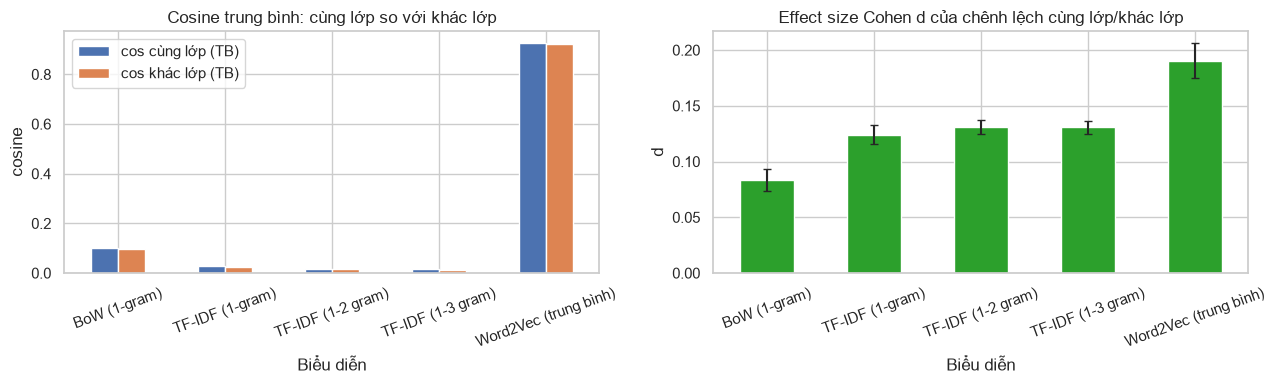

In [4]:
def within_subset_cosine(X, subset: np.ndarray) -> dict:
    """Cosine của mọi cặp trong một tập con: trung bình cùng lớp / khác lớp và Cohen d."""
    Xn = normalize(X[subset])
    S = (Xn @ Xn.T)
    S = S.toarray() if sparse.issparse(S) else S
    yy = y_test[subset]
    upper = np.triu(np.ones_like(S, dtype=bool), k=1)
    same = upper & (yy[:, None] == yy[None, :])
    diff = upper & (yy[:, None] != yy[None, :])
    cs, cd = S[same], S[diff]
    pooled = np.sqrt(((len(cs) - 1) * cs.var(ddof=1) + (len(cd) - 1) * cd.var(ddof=1)) / (len(cs) + len(cd) - 2))
    return {"cos cùng lớp": cs.mean(), "cos khác lớp": cd.mean(), "Δ": cs.mean() - cd.mean(), "Cohen d": (cs.mean() - cd.mean()) / pooled}


folds = np.array_split(np.random.default_rng(config.SEED).permutation(len(test)), 10)
cos_rows = {}
for name, X in REP_TEST.items():
    per_fold = pd.DataFrame([within_subset_cosine(X, f) for f in folds])
    cos_rows[name] = {**{f"{k} (TB)": per_fold[k].mean() for k in per_fold}, "SD(Δ) giữa 10 tập": per_fold["Δ"].std(ddof=1), "SD(d) giữa 10 tập": per_fold["Cohen d"].std(ddof=1)}
cos_table = pd.DataFrame(cos_rows).T
display(cos_table.round(5))
RESULTS["cosine_table"] = cos_table.round(8).to_dict("index")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
cos_table[["cos cùng lớp (TB)", "cos khác lớp (TB)"]].plot.bar(ax=axes[0], rot=20)
axes[0].set_title("Cosine trung bình: cùng lớp so với khác lớp"); axes[0].set_ylabel("cosine"); axes[0].set_xlabel("Biểu diễn")
cos_table["Cohen d (TB)"].plot.bar(ax=axes[1], rot=20, color="tab:green", yerr=cos_table["SD(d) giữa 10 tập"], capsize=3)
axes[1].set_title("Effect size Cohen d của chênh lệch cùng lớp/khác lớp"); axes[1].set_ylabel("d"); axes[1].set_xlabel("Biểu diễn")
plt.tight_layout()
plt.show()

**Phân tích kết quả** (10 tập con của tập test, mỗi tập khoảng 990 review).

| Biểu diễn | cosine cùng lớp | cosine khác lớp | $\Delta$ | Cohen $d$ ± SD giữa 10 tập |
|---|---|---|---|---|
| BoW (1-gram) | 0.10198 | 0.09670 | 0.00529 | 0.0832 ± 0.0100 |
| TF-IDF (1-gram) | 0.02832 | 0.02593 | 0.00239 | 0.1242 ± 0.0081 |
| TF-IDF (1-2 gram) | 0.01602 | 0.01461 | 0.00142 | 0.1309 ± 0.0061 |
| TF-IDF (1-3 gram) | 0.01539 | 0.01402 | 0.00136 | 0.1306 ± 0.0057 |
| Word2Vec (trung bình) | 0.92654 | 0.92075 | 0.00579 | **0.1905 ± 0.0160** |
| Sentence Transformer (6.4) | 0.2978 | 0.2870 | 0.0108 | 0.1016 ± 0.0131 |

- **Giá trị cosine thô không so sánh được giữa các biểu diễn.** Mức nền khác nhau rất xa: 0.016 đến 0.028 với TF-IDF (vector thưa, hai review hiếm khi chung nhiều từ), 0.10 với BoW, khoảng 0.29 với Sentence Transformer và tới 0.93 với Word2Vec (trung bình vector từ làm mọi review giống nhau). Vì vậy ta so sánh bằng Cohen $d$, đã chuẩn hóa theo độ phân tán.
- **Cả sáu biểu diễn đều có cosine cùng lớp cao hơn khác lớp, nhưng chênh lệch rất nhỏ** (Cohen $d$ từ 0.08 đến 0.19, đều dưới ngưỡng 0.2 thường gọi là "nhỏ"). Tức độ tương đồng giữa hai review chủ yếu do **chủ đề, thể loại và từ vựng** quyết định chứ không phải do cảm xúc: hai review phim kinh dị trái cảm xúc vẫn giống nhau hơn một review kinh dị và một review hài cùng cảm xúc.
- **Word2Vec cho $d$ lớn nhất (0.1905)**, hơn TF-IDF (1-2 gram) khoảng 0.060, tức khoảng 3.7 lần độ biến thiên giữa các tập con (SD = 0.0160), nên khác biệt này khá vững. Giải thích hợp lý (chưa kiểm chứng riêng): trung bình hóa vector từ khuếch đại các từ cảm xúc xuất hiện ở khắp review.
- **TF-IDF tốt hơn BoW** ($d$ = 0.1242 so với 0.0832, tăng khoảng 49%) vì IDF giảm trọng số các từ phổ biến vốn chi phối cosine của vector đếm thô. **Thêm n-gram chỉ cải thiện rất ít:** $(1,2)$ cho 0.1309 và $(1,3)$ cho 0.1306, chênh so với 1-gram (0.0067 và 0.0064) cùng bậc với độ biến thiên giữa các tập con (0.006 đến 0.008), nên ta không kết luận được n-gram có tốt hơn. Điều này nhất quán với 6.1: trigram gần như không thêm thông tin vì quá hiếm.
- **Không báo p-value** vì các cặp review dùng chung tài liệu nên không độc lập; độ biến thiên giữa 10 tập con là thước đo bất định thay thế, và đây chỉ là so sánh mô tả.

## Lưu kết quả

Toàn bộ con số của chương được ghi ra `data/processed/results/` để chương báo cáo tham chiếu.

In [5]:
config.save_results("06_text_representation", RESULTS)
RESULTS

{'n_train': 39662,
 'n_test': 9916,
 'n_labeled_subset': 10000,
 'rep_table': {'BoW (1-gram)': {'số chiều': 32951.0,
   'nnz / review': 96.99969746,
   'sparsity ratio': 0.99705624,
   'thời gian fit (s)': 6.34998417},
  'TF-IDF (1-gram)': {'số chiều': 32951.0,
   'nnz / review': 96.99969746,
   'sparsity ratio': 0.99705624,
   'thời gian fit (s)': 7.04920053},
  'TF-IDF (1-2 gram)': {'số chiều': 143441.0,
   'nnz / review': 135.99455426,
   'sparsity ratio': 0.99905191,
   'thời gian fit (s)': 17.71199393},
  'TF-IDF (1-3 gram)': {'số chiều': 158199.0,
   'nnz / review': 138.97398144,
   'sparsity ratio': 0.99912152,
   'thời gian fit (s)': 28.41150641},
  'Word2Vec (trung bình)': {'số chiều': 100.0,
   'nnz / review': 100.0,
   'sparsity ratio': 0.0,
   'thời gian fit (s)': 217.0184145}},
 'w2v_vocab': 36875,
 'w2v_zero_docs_test': 0,
 'w2v_neighbors': {'good': ['decent', 'great', 'bad', 'downsides', 'godawful'],
  'bad': ['terrible', 'awful', 'horrible', 'lousy', 'good'],
  'terribl